In [1]:
import csv
import random
from pathlib import Path

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt


from io import BytesIO

from PIL import Image
from datasets import load_dataset
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from torchvision.models import (
    convnext_small,
    ConvNeXt_Small_Weights
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tqdm.auto import tqdm

In [2]:
DATASET_NAME = "saberzl/SID_Set"

SEED = 42
IMAGE_SIZE = (450, 450)

TARGET_PER_CLASS = {
    0: 40_334,
    1: 40_333,
    2: 40_333,
}

CLASS_NAMES = {
    0: "real",
    1: "full_synthetic",
    2: "tampered",
}

In [3]:
PROCESSED_DIR = Path(
    "/kaggle/working/sid_set_50000_processed"
)

CSV_PATH = PROCESSED_DIR / "labels.csv"

TOTAL_TARGET = sum(
    TARGET_PER_CLASS.values()
)

print("Total target:", TOTAL_TARGET)

Total target: 121000


In [4]:
SPLIT_QUOTAS = {}

for label, total in TARGET_PER_CLASS.items():

    train_n = round(
        total * 0.70
    )

    val_n = round(
        total * 0.15
    )

    test_n = (
        total
        - train_n
        - val_n
    )

    SPLIT_QUOTAS[label] = {
        "train": train_n,
        "val": val_n,
        "test": test_n,
    }

SPLIT_QUOTAS

{0: {'train': 28234, 'val': 6050, 'test': 6050},
 1: {'train': 28233, 'val': 6050, 'test': 6050},
 2: {'train': 28233, 'val': 6050, 'test': 6050}}

In [5]:
SPLIT_PLAN = {}

for label, quotas in SPLIT_QUOTAS.items():

    plan = (
        ["train"] * quotas["train"]
        + ["val"] * quotas["val"]
        + ["test"] * quotas["test"]
    )

    random.Random(
        SEED + label
    ).shuffle(plan)

    SPLIT_PLAN[label] = plan

In [6]:
if CSV_PATH.exists():

    raise FileExistsError(
        f"Dataset already exists at: {PROCESSED_DIR}"
    )


for split in (
    "train",
    "val",
    "test"
):

    for class_name in CLASS_NAMES.values():

        (
            PROCESSED_DIR
            / split
            / class_name
        ).mkdir(
            parents=True,
            exist_ok=True
        )

In [7]:
dataset = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True,
)


print(dataset)

README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/249 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/34 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/249 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/34 [00:00<?, ?it/s]

IterableDataset({
    features: ['img_id', 'image', 'mask', 'width', 'height', 'label'],
    num_shards: 249
})


In [8]:
def to_pil_image(image):

    if isinstance(
        image,
        Image.Image
    ):

        return image.convert(
            "RGB"
        )


    if isinstance(
        image,
        bytes
    ):

        return Image.open(
            BytesIO(image)
        ).convert(
            "RGB"
        )


    if isinstance(
        image,
        dict
    ):

        if image.get(
            "bytes"
        ) is not None:

            return Image.open(
                BytesIO(
                    image["bytes"]
                )
            ).convert(
                "RGB"
            )


        if image.get(
            "path"
        ) is not None:

            return Image.open(
                image["path"]
            ).convert(
                "RGB"
            )


    raise TypeError(
        f"Unsupported image type: {type(image)}"
    )

In [9]:
counts = {
    label: 0
    for label in TARGET_PER_CLASS
}


split_counts = {

    label: {
        "train": 0,
        "val": 0,
        "test": 0
    }

    for label in TARGET_PER_CLASS
}


metadata = []

In [10]:
progress = tqdm(
    total=TOTAL_TARGET,
    desc="Processing dataset",
)

Processing dataset:   0%|          | 0/121000 [00:00<?, ?it/s]

In [11]:
for sample in dataset:

    try:

        label = int(
            sample["label"]
        )

        if label not in TARGET_PER_CLASS:
            continue

        if (
            counts[label]
            >= TARGET_PER_CLASS[label]
        ):
            continue

        split_name = SPLIT_PLAN[
            label
        ][
            counts[label]
        ]

        image = to_pil_image(
            sample["image"]
        )

        image = image.resize(
            IMAGE_SIZE,
            Image.Resampling.BILINEAR
        )

        class_name = CLASS_NAMES[
            label
        ]

        index_in_split = (
            split_counts[
                label
            ][
                split_name
            ]
        )

        output_dir = (
            PROCESSED_DIR
            / split_name
            / class_name
        )

        filename = (
            f"{class_name}_"
            f"{index_in_split:06d}.jpg"
        )

        output_path = (
            output_dir
            / filename
        )

        image.save(
            output_path,
            format="JPEG",
            quality=95
        )

        metadata.append({
            "path": str(
                output_path.relative_to(
                    PROCESSED_DIR
                )
            ),
            "label": label,
            "class_name": class_name,
            "split": split_name
        })

        counts[label] += 1

        split_counts[
            label
        ][
            split_name
        ] += 1

        progress.update(1)

        if all(
            counts[label]
            >= TARGET_PER_CLASS[label]
            for label in TARGET_PER_CLASS
        ):
            break

    except Exception as e:

        print(
            f"Skipped sample: {e}"
        )

progress.close()

'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/saberzl/SID_Set/resolve/dc03ead57929879319ce30a82bfcfb8d317b10bd/data/train-00001-of-00249.parquet
Retrying in 1s [Retry 1/5].


In [12]:
print("Per-class counts:")

print(counts)


print("\nSplit counts:")

print(split_counts)


print(
    "\nTotal:",
    sum(counts.values())
)

Per-class counts:
{0: 40334, 1: 40333, 2: 40333}

Split counts:
{0: {'train': 28234, 'val': 6050, 'test': 6050}, 1: {'train': 28233, 'val': 6050, 'test': 6050}, 2: {'train': 28233, 'val': 6050, 'test': 6050}}

Total: 121000


In [13]:
with open(
    CSV_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "path",
            "label",
            "class_name",
            "split"
        ],
    )

    writer.writeheader()

    writer.writerows(
        metadata
    )


print(
    "Saved:",
    CSV_PATH
)

Saved: /kaggle/working/sid_set_50000_processed/labels.csv


In [14]:
total_saved = 0


for split in (
    "train",
    "val",
    "test"
):

    split_total = 0

    print(
        f"\n{split.upper()}"
    )


    for class_name in CLASS_NAMES.values():

        folder = (
            PROCESSED_DIR
            / split
            / class_name
        )


        count = len(
            list(
                folder.glob(
                "*.jpg"
            )
                     )
        )


        split_total += count


        print(
            f"{class_name}: {count}"
        )


    total_saved += split_total


    print(
        f"Total {split}: {split_total}"
    )


print(
    "\nTotal saved:",
    total_saved
)


print(
    "Expected:",
    TOTAL_TARGET
)


assert (
    total_saved
    == TOTAL_TARGET
)


TRAIN
real: 28234
full_synthetic: 28233
tampered: 28233
Total train: 84700

VAL
real: 6050
full_synthetic: 6050
tampered: 6050
Total val: 18150

TEST
real: 6050
full_synthetic: 6050
tampered: 6050
Total test: 18150

Total saved: 121000
Expected: 121000


In [15]:


DATA_DIR = PROCESSED_DIR

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR   = DATA_DIR / "val"
TEST_DIR  = DATA_DIR / "test"




In [16]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

print("Classes:", train_dataset.classes)
print("Mapping:", train_dataset.class_to_idx)

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

Classes: ['full_synthetic', 'real', 'tampered']
Mapping: {'full_synthetic': 0, 'real': 1, 'tampered': 2}
Train: 84700
Val: 18150
Test: 18150


In [28]:
BATCH_SIZE = 32
NUM_WORKERS = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4
)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [29]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [30]:
from torchvision.models import (
    convnext_base,
    ConvNeXt_Base_Weights
)

weights = ConvNeXt_Base_Weights.IMAGENET1K_V1

model = convnext_base(
    weights=weights
)

model.classifier[2] = nn.Linear(
    model.classifier[2].in_features,
    3
)

model = model.float().to(device)

print(model.classifier)

Sequential(
  (0): LayerNorm2d((1024,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=1024, out_features=3, bias=True)
)


In [31]:
# Freeze كل الموديل
for param in model.parameters():
    param.requires_grad = False

# فتح آخر أجزاء ConvNeXt
for param in model.features[-2:].parameters():
    param.requires_grad = True

# فتح classifier
for param in model.classifier.parameters():
    param.requires_grad = True

In [32]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

Total parameters: 87,569,539
Trainable parameters: 27,448,323
Trainable percentage: 31.34%


In [33]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-3
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

In [34]:
from tqdm.auto import tqdm

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        loader,
        desc="Training"
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{correct / total:.2%}"
        )

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [35]:
def evaluate(
    model,
    loader,
    criterion,
    device,
    desc="Validation"
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        progress = tqdm(
            loader,
            desc=desc
        )

        for images, labels in progress:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [36]:
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/kaggle/working/convnext_base_checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

best_val_loss = float("inf")
best_val_acc = 0.0

epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print(CHECKPOINT_DIR)

/kaggle/working/convnext_base_checkpoints


In [37]:
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Optimizer, scheduler, scaler ready")

Optimizer, scheduler, scaler ready


In [38]:
EPOCHS = 10
PATIENCE = 2

for epoch in range(EPOCHS):

    print()
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("=" * 60)

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        scaler,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device,
        desc="Validation"
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print()
    print(f"Train Loss:     {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2%}")

    print(f"Val Loss:       {val_loss:.4f}")
    print(f"Val Accuracy:   {val_acc:.2%}")

    print(
        "Learning Rate:",
        optimizer.param_groups[0]["lr"]
    )

    checkpoint = {
        "epoch": epoch + 1,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "train_loss":
            train_loss,

        "train_acc":
            train_acc,

        "val_loss":
            val_loss,

        "val_acc":
            val_acc,

        "classes":
            train_dataset.classes,

        "class_to_idx":
            train_dataset.class_to_idx
    }

    # حفظ checkpoint لكل epoch
    torch.save(
        checkpoint,
        CHECKPOINT_DIR /
        f"checkpoint_epoch_{epoch + 1}.pth"
    )

    print(
        f"Checkpoint saved: epoch {epoch + 1}"
    )

    # أفضل Val Loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save(
            checkpoint,
            CHECKPOINT_DIR /
            "best_loss_model.pth"
        )

        print("Best loss model updated.")

    else:

        epochs_without_improvement += 1

    # أفضل Accuracy
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            checkpoint,
            CHECKPOINT_DIR /
            "best_accuracy_model.pth"
        )

        print("Best accuracy model updated.")

    print(
        f"No loss improvement: "
        f"{epochs_without_improvement}/{PATIENCE}"
    )

    if epochs_without_improvement >= PATIENCE:

        print()
        print("Early stopping triggered.")
        break


Epoch 1/10


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Training:   0%|          | 0/2647 [00:00<?, ?it/s]

Validation:   0%|          | 0/568 [00:00<?, ?it/s]


Train Loss:     0.4775
Train Accuracy: 82.01%
Val Loss:       0.2548
Val Accuracy:   89.92%
Learning Rate: 1e-05
Checkpoint saved: epoch 1
Best loss model updated.
Best accuracy model updated.
No loss improvement: 0/2

Epoch 2/10


...

Validation:   0%|          | 0/568 [00:00<?, ?it/s]


Train Loss:     0.1574
Train Accuracy: 93.99%
Val Loss:       0.1453
Val Accuracy:   94.44%
Learning Rate: 1e-05
Checkpoint saved: epoch 9
Best loss model updated.
Best accuracy model updated.
No loss improvement: 0/2

Epoch 10/10


Training:   0%|          | 0/2647 [00:00<?, ?it/s]

Validation:   0%|          | 0/568 [00:00<?, ?it/s]


Train Loss:     0.1497
Train Accuracy: 94.18%
Val Loss:       0.1451
Val Accuracy:   94.45%
Learning Rate: 1e-05
Checkpoint saved: epoch 10
Best loss model updated.
Best accuracy model updated.
No loss improvement: 0/2


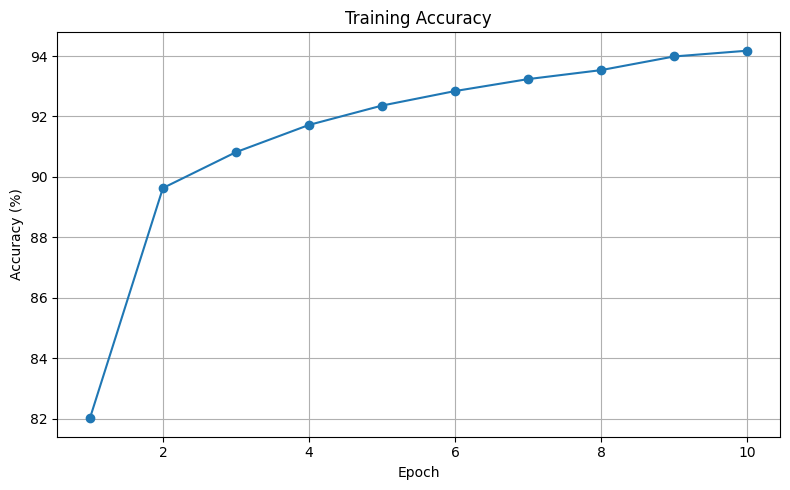

In [39]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)



plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [acc * 100 for acc in history["train_acc"]],
    marker="o"
)

plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.show()








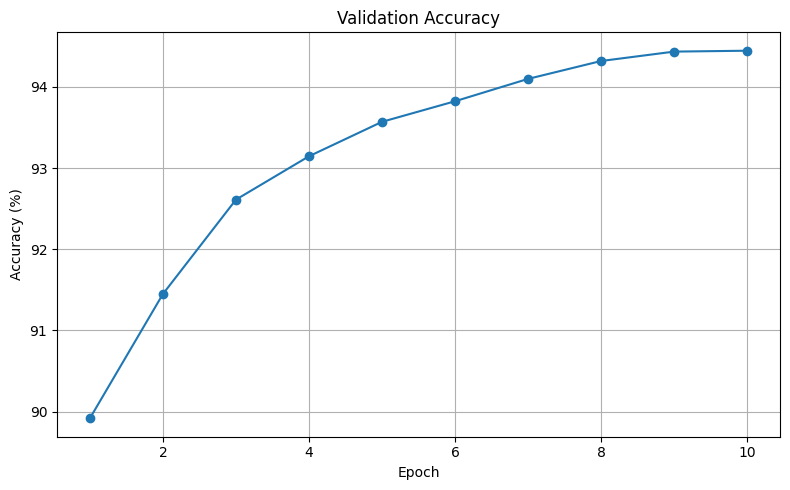

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [acc * 100 for acc in history["val_acc"]],
    marker="o"
)

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.show()


Test Accuracy: 0.9424
Test Accuracy: 94.24%

Classification Report:

                precision    recall  f1-score   support

          real       0.92      0.91      0.91      6050
full_synthetic       1.00      1.00      1.00      6050
      tampered       0.91      0.92      0.92      6050

      accuracy                           0.94     18150
     macro avg       0.94      0.94      0.94     18150
  weighted avg       0.94      0.94      0.94     18150



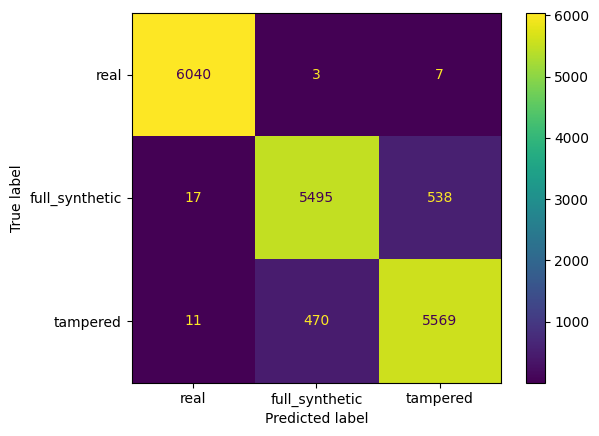

In [41]:
# Test the trained model

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Accuracy
accuracy = (
    np.array(all_preds) == np.array(all_labels)
).mean()

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Classification Report
print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_preds,
    labels=[1, 0, 2],
    target_names=["real", "full_synthetic", "tampered"]
))

# Confusion Matrix
cm = confusion_matrix(
    all_labels,
    all_preds
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "real",
        "full_synthetic",
        "tampered"
    ]
)

disp.plot()
plt.show()

In [42]:
import torch
from pathlib import Path
from torchvision.models import convnext_base

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CHECKPOINT_DIR = Path(
    "/kaggle/working/convnext_base_checkpoints"
)

checkpoint_files = (
    list(CHECKPOINT_DIR.glob("*.pth"))
    + list(CHECKPOINT_DIR.glob("*.pt"))
)

if not checkpoint_files:
    raise FileNotFoundError("No checkpoints found!")

best_checkpoint_path = None
best_val_acc = -1

for checkpoint_path in checkpoint_files:

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu"
    )

    val_acc = checkpoint["val_acc"]

    if torch.is_tensor(val_acc):
        val_acc = val_acc.item()

    print(
        f"{checkpoint_path.name} -> "
        f"Epoch: {checkpoint['epoch']} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_checkpoint_path = checkpoint_path


print("\nBest checkpoint:")
print(best_checkpoint_path)

print(
    f"Best Val Acc: {best_val_acc:.4f}"
)


# إنشاء نفس الموديل
model = convnext_base(
    weights=None
)

model.classifier[2] = torch.nn.Linear(
    model.classifier[2].in_features,
    len(checkpoint["classes"])
)


# تحميل أفضل checkpoint
best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

CLASS_NAMES = best_checkpoint["classes"]



checkpoint_epoch_7.pth -> Epoch: 7 | Val Acc: 0.9410
checkpoint_epoch_2.pth -> Epoch: 2 | Val Acc: 0.9145
checkpoint_epoch_1.pth -> Epoch: 1 | Val Acc: 0.8992
best_accuracy_model.pth -> Epoch: 10 | Val Acc: 0.9445
checkpoint_epoch_4.pth -> Epoch: 4 | Val Acc: 0.9315
checkpoint_epoch_5.pth -> Epoch: 5 | Val Acc: 0.9357
checkpoint_epoch_10.pth -> Epoch: 10 | Val Acc: 0.9445
checkpoint_epoch_8.pth -> Epoch: 8 | Val Acc: 0.9432
checkpoint_epoch_9.pth -> Epoch: 9 | Val Acc: 0.9444
checkpoint_epoch_6.pth -> Epoch: 6 | Val Acc: 0.9382
checkpoint_epoch_3.pth -> Epoch: 3 | Val Acc: 0.9261
best_loss_model.pth -> Epoch: 10 | Val Acc: 0.9445

Best checkpoint:
/kaggle/working/convnext_base_checkpoints/best_accuracy_model.pth
Best Val Acc: 0.9445


In [46]:
import os
import torch

from PIL import Image
from torchvision import transforms


IMAGE_SIZE = (350, 350)

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


wanted_files = [
    "ChatGPT Image Sep 15 2026 04_36_41 PM.png",
    "artem-maltsev-Fo6ueGnwOsU-unsplash.jpg",
    "pexels-scottwebb-1029598.jpg",
    "jonny-gios-pfzJIn6wVas-unsplash.jpg",
    "Artificial_intelligence_in_education.jpg",
    
]


image_paths = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file in wanted_files:
            image_paths.append(
                os.path.join(root, file)
            )


model.eval()


for image_path in image_paths:

    image = Image.open(
        image_path
    ).convert("RGB")

    image = image.resize(
        IMAGE_SIZE,
        Image.Resampling.BILINEAR
    )

    input_tensor = eval_transform(
        image
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        output = model(
            input_tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        confidence, predicted = torch.max(
            probabilities,
            dim=1
        )

    predicted_class = CLASS_NAMES[
        predicted.item()
    ]

    confidence = confidence.item() * 100

    print(
        f"{os.path.basename(image_path)}"
        f" -> {predicted_class}"
        f" ({confidence:.2f}%)"
    )

Artificial_intelligence_in_education.jpg -> full_synthetic (49.51%)
jonny-gios-pfzJIn6wVas-unsplash.jpg -> real (90.66%)
artem-maltsev-Fo6ueGnwOsU-unsplash.jpg -> full_synthetic (53.06%)
ChatGPT Image Sep 15 2026 04_36_41 PM.png -> real (70.01%)
pexels-scottwebb-1029598.jpg -> real (94.74%)
